# Задание 1. Пропущенные значения и корреляции

Весь вычислительный код лежит в пакете [`t1lib`](t1lib), ноутбук — только сценарий:
генерируем датасет, ломаем его, восстанавливаем разными методами и смотрим,
что при этом происходит с корреляциями.

| Пункт | Что делаем | Где код |
|---|---|---|
| [1.1] | `dfS00`: 4 количественных признака, 1 класс из 1000 объектов, `r(A,B)=+0.9` | `t1lib/datagen.py` |
| [1.2] | Табличная статистика датасета | `t1lib/stats.py` |
| [1.3] | Raincloud plot с jittering + boxplot | `raincloudkit` (`../raincloud_plot`) через `t1lib/viz.py` |
| [1.4] | Scatter-матрица со настраиваемыми параметрами | `scatterkit` (`../scatter_plot`) через `t1lib/viz.py` |
| [1.5] | Heatmap корреляций Пирсона и Спирмена | `t1lib/stats.py` |
| [1.6] | `dfSdXX`: случайное удаление 0–80% ячеек | `t1lib/datagen.py` |
| [1.7] | `dfSdXXmed`: заполнение медианой | `t1lib/impute.py` |
| [1.8] | Медиана / kNN / регрессия / MICE | `t1lib/impute.py` |
| [1.9] | **UpSet plot** (через собственный модуль `upsetkit`) | `t1lib/upsetviews.py` |
| [1.10] | `dfMNAR`: удаление значений ниже медианы | `t1lib/datagen.py` |

In [1]:
# Только для Google Colab: подтягиваем репозиторий с t1lib и библиотеками
# upsetkit, raincloudkit, scatterkit.
# Локально эта ячейка ничего не делает.
import os, sys
if "google.colab" in sys.modules:
    REPO = "/content/tsr"
    if not os.path.exists(REPO):
        !git clone -q https://github.com/LessVegetables/tsr.git {REPO}
    %pip install -q {REPO}/upset_plotting {REPO}/raincloud_plot {REPO}/scatter_plot
    os.chdir(f"{REPO}/task1")
    sys.path.insert(0, os.getcwd())

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

import t1lib
from t1lib import (
    BoxSpec, DatasetSpec, RAIN_STYLE, SCATTER_STYLE,
    make_base_dataset, make_mcar_family, make_mnar_below_median,
    describe_dataset, correlation_tables, plot_correlation_heatmaps,
    raincloud_grid, scatter_matrix, scatter_panel, set_tick_step,
    impute, impute_family,
    upset_missing, upset_duplicated_values, upset_pairwise_equal,
)
from t1lib.impute import RU_NAMES, imputation_error, median_family
from t1lib.stats import pair_support
from t1lib.upsetviews import intersections_table, upset_series

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams["figure.max_open_warning"] = 0
pd.set_option("display.width", 140, "display.max_columns", 40)

# MICE берёт выборку из апостериорного распределения на каждом проходе, поэтому
# критерий раннего останова принципиально не достигается — это не ошибка.
warnings.filterwarnings("ignore", message=".*Early stopping criterion not reached.*")

# ============================ ПАРАМЕТРЫ ПОЛЬЗОВАТЕЛЯ ============================
RANDOM_STATE = 42
PAIR_1 = ("A", "B")            # [1.6]-[1.8]: основная пара (коррелированная)
PAIR_2 = ("C", "D")            # [1.8]: вторая пара (независимая)
SHARES = (0.0, 0.01, 0.02, 0.05, 0.10, 0.20, 0.50, 0.80)   # [1.6]
CHOSEN = "dfSd20"              # [1.8]: какой dfSdXX разбираем подробно
METHODS = ("med", "knn", "reg", "mice")                     # [1.8]
PANEL_NCOLS = 4                # ширина панно m x n
RAIN = RAIN_STYLE              # [1.3] raincloudkit.RainStyle — все поля в ../raincloud_plot/README.md
SCATTER = SCATTER_STYLE        # [1.4]-[1.10] scatterkit.Style — все поля в ../scatter_plot/config.example.txt
# ===============================================================================

print("t1lib загружен:", Path(t1lib.__file__).parent)

t1lib загружен: /Users/danielgehrman/Documents/Programming/Uni/actual_ml/task1/t1lib


## [1.1] Генерация датасета `dfS00`

По условию в датасете **один класс** из 1000 объектов, поэтому выборка
получается одним вызовом `numpy.random.Generator.multivariate_normal` с
нулевыми средними и ковариацией, в которой сидит `r(A,B)=+0.9`; остальные
пары признаков не сопряжены. Столбец класса (`target`, единственное значение
`K0`) всё равно хранится: разрезы «по классам» из [1.2] и [1.5] на нём
работают и честно показывают один класс.

`DatasetSpec` умеет и несколько классов (их средние разносятся в плоскости
`C`–`D` так, чтобы межклассовая ковариация не добавляла ложных корреляций), но
в этом задании используется ровно один.

In [3]:
spec = DatasetSpec(
    features=("A", "B", "C", "D"),
    n=1000,
    class_names=("K0",),            # по условию — один класс
    corr_pair=PAIR_1,
    corr=0.9,
    stds=(1.0, 1.5, 2.0, 0.8),
    random_state=RANDOM_STATE,
)

display(Markdown("**Заданная корреляционная матрица:**"))
display(spec.correlation_matrix())

dfS00 = make_base_dataset(spec)
FEATURES = list(spec.features)
CLASS_COL = spec.class_col
dfS00.head()

**Заданная корреляционная матрица:**

,A,B,C,D
A,1.0,0.9,0.0,0.0
B,0.9,1.0,0.0,0.0
C,0.0,0.0,1.0,0.0
D,0.0,0.0,0.0,1.0


,A,B,C,D,target
0,-0.592069,-1.248634,2.044814,-0.076229,K0
1,-1.346525,-1.587682,1.452058,-0.935741,K0
2,0.255988,-0.106140,-2.538179,0.243548,K0
3,0.382315,-0.060251,1.177280,-0.775519,K0
4,-0.416013,0.153909,-2.984212,-0.095335,K0


In [4]:
# Проверяем, что заказанная структура действительно получилась
pairs = [(a, b) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]]
scopes = {"весь датасет": dfS00,
          **{f"класс {k}": g for k, g in dfS00.groupby(CLASS_COL, observed=True)}}
check = pd.DataFrame(
    {scope: [round(d[a].corr(d[b]), 3) for a, b in pairs] for scope, d in scopes.items()},
    index=pd.MultiIndex.from_tuples(pairs),
)
display(check)

r = dfS00[PAIR_1[0]].corr(dfS00[PAIR_1[1]])
others = [abs(dfS00[a].corr(dfS00[b])) for a, b in pairs if (a, b) != tuple(PAIR_1)]
print(f"r{PAIR_1} = {r:.3f} (заказано {spec.corr});  "
      f"max |r| по остальным парам = {max(others):.3f}")

весь датасет  класс K0
A B         0.896     0.896
  C        -0.027    -0.027
  D        -0.040    -0.040
B C        -0.014    -0.014
  D        -0.013    -0.013
C D         0.010     0.010

r('A', 'B') = 0.896 (заказано 0.9);  max |r| по остальным парам = 0.040


## [1.2] Табличная статистика

`describe_dataset()` возвращает все шесть таблиц, которые перечислены в условии.

Про нули: признаки — непрерывные нормальные величины, вероятность попасть точно
в `0.0` равна нулю, поэтому столбец «exact 0» честно пустой. Рядом стоит счётчик
`|x| <= atol` — та же метрика, но с допуском; на `dfS00` он тоже нулевой, а вот
после заполнения пропусков константой становится информативным.

In [5]:
for caption, table in describe_dataset(dfS00, CLASS_COL, FEATURES).items():
    display(Markdown(f"**{caption}**"))
    display(table)

**Размерность**

,value
objects (rows),1000
columns,5
features,4
classes,1


**Типы признаков**

,dtype,role,unique,non-null
A,float64,feature,1000,1000
B,float64,feature,1000,1000
C,float64,feature,1000,1000
D,float64,feature,1000,1000
target,category,class,1,1000


**Классы**

...

,count,mean,std,min,25%,50%,75%,max,IQR,range,skew,kurtosis,missing,"missing, %"
A,1000.0,0.0093,0.9886,-3.1169,-0.6514,0.0062,0.6418,3.7230,1.2931,6.8399,0.0661,0.2182,0,0.0
B,1000.0,0.0030,1.5070,-4.4563,-0.9814,-0.0587,0.9820,5.5141,1.9634,9.9704,0.1168,0.2393,0,0.0
C,1000.0,-0.0318,1.9529,-5.9291,-1.3015,-0.0823,1.2272,6.1770,2.5288,12.1061,0.1287,0.1058,0,0.0
D,1000.0,-0.0329,0.8088,-2.2101,-0.6015,0.0062,0.5119,2.5431,1.1134,4.7532,0.0117,-0.2346,0,0.0


**Объекты с NaN по классам**

,A,B,C,D,rows with >=1 NaN,rows fully complete
target,,,,,,
K0,0,0,0,0,0,1000


**Объекты с нулями по классам**

exact 0          |x| <= 1e-12         
             A  B  C  D            A  B  C  D
target                                       
K0           0  0  0  0            0  0  0  0

## [1.3] 1D визуализация: raincloud plot с jittering

Рисует `plot_raincloud()` из **`raincloudkit`** (`../raincloud_plot`): по панели на
признак, в каждой — «облако» (половина KDE), «дождь» (сами объекты с
джиттером) и ящик со сводными оценками. Число рядом с ящиком — значение центра.

Оценки в ящике задаются через `BoxSpec` из `raincloudkit` и **заменяются на
другие**: центр — медиана / среднее / квантиль / произвольная функция; тело
ящика — IQR / ±std / ±SEM / ci95 / пара процентилей; усы — полный размах /
1.5·IQR / ±std / пара процентилей. Внешний вид — поля `RainStyle`
(`RAIN.derive(...)`).

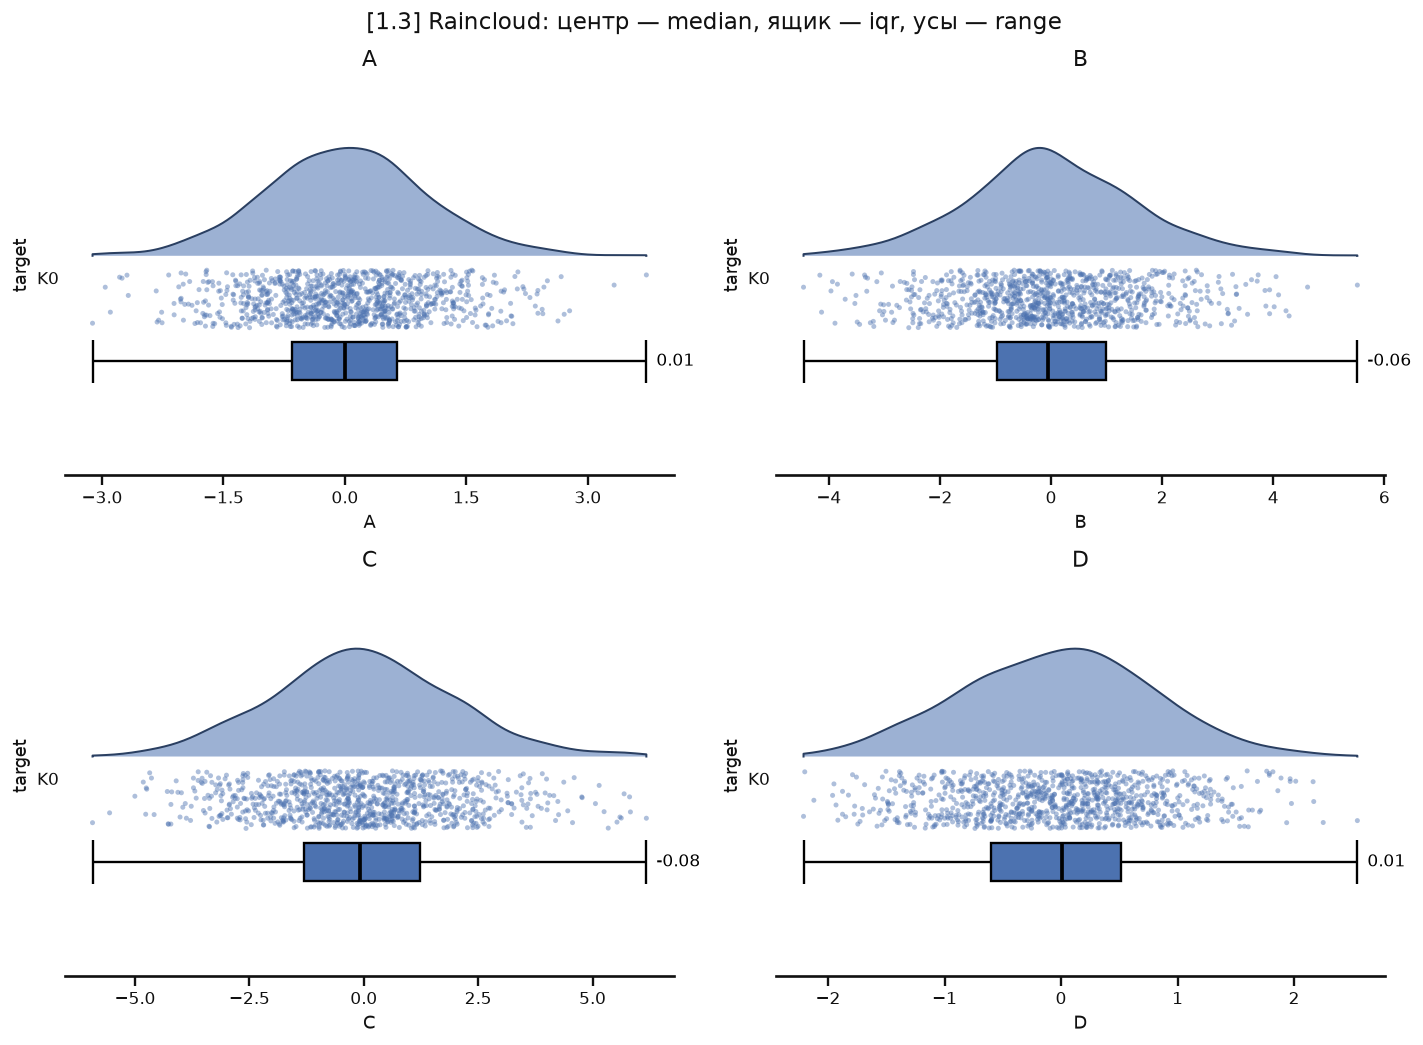

In [6]:
fig = raincloud_grid(
    dfS00, FEATURES, class_col=CLASS_COL,
    box=BoxSpec(center="median", box="iqr", whisker="range"),   # медиана, IQR, Range
    style=RAIN, ncols=2,
)
fig.savefig(FIG / "1.3_raincloud_median_iqr_range.png", bbox_inches="tight", dpi=120)
plt.show()

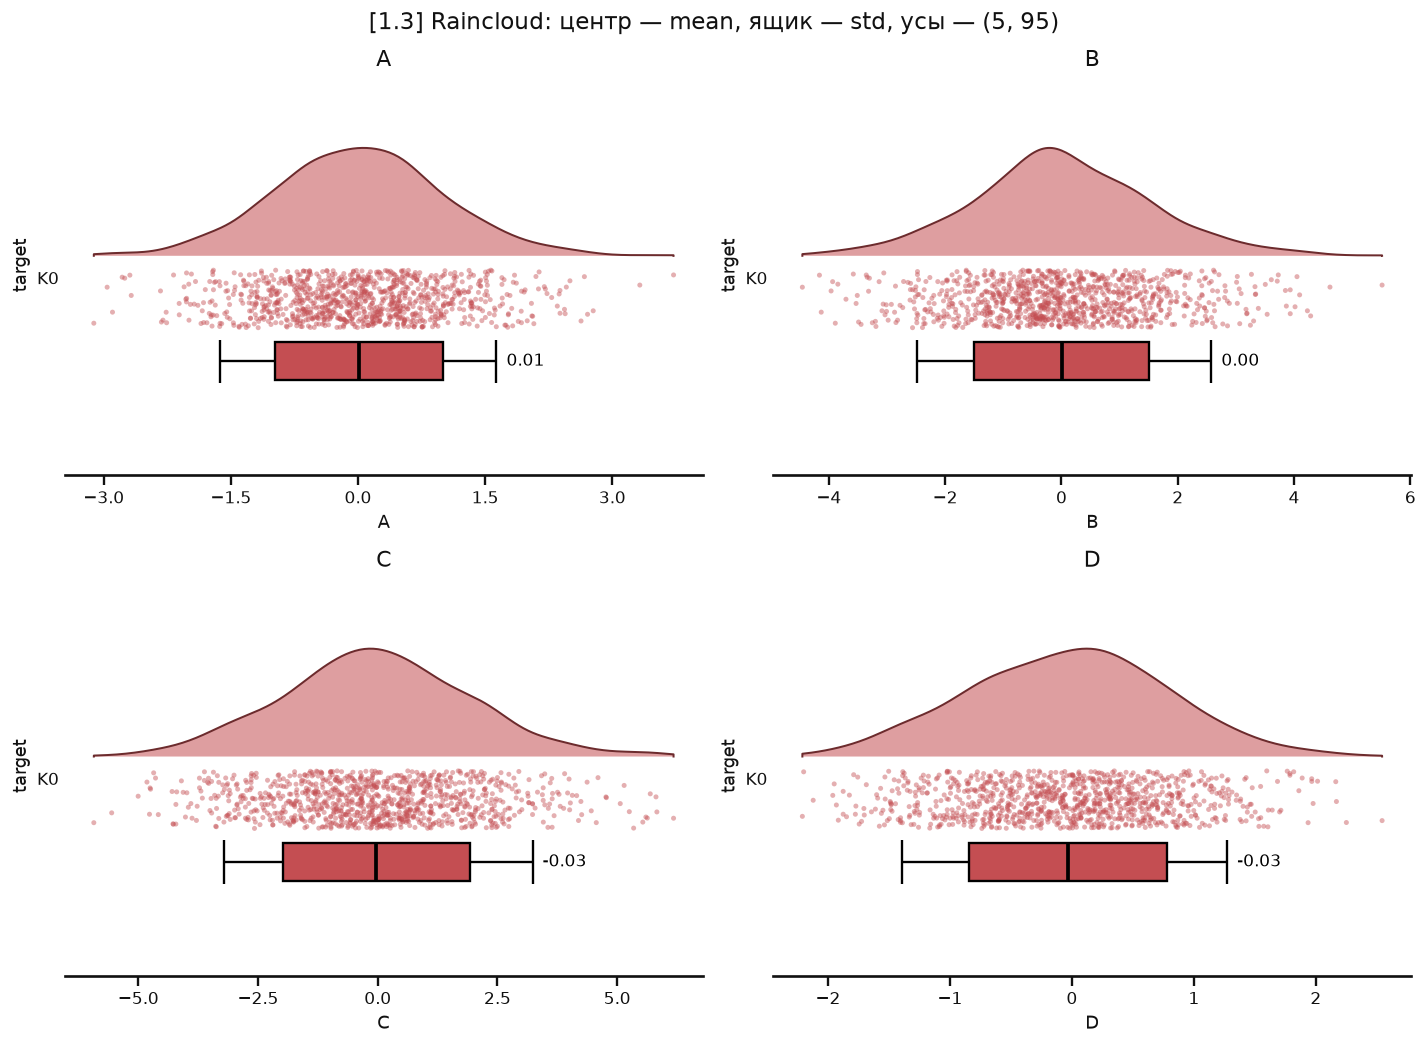

In [7]:
# Те же данные, другие оценки выборки: среднее, ±std, перцентили 5–95
fig = raincloud_grid(
    dfS00, FEATURES, class_col=CLASS_COL,
    box=BoxSpec(center="mean", box="std", whisker=(5, 95)),
    style=RAIN.derive(palette=("#C44E52",)),
    ncols=2,
)
fig.savefig(FIG / "1.3_raincloud_mean_std_p5p95.png", bbox_inches="tight", dpi=120)
plt.show()

## [1.4] 2D визуализация: scatter-матрица

Рисует `plot_scatter_matrix()` из **`scatterkit`** (`../scatter_plot`):

* вне диагонали — пары признаков; каждый класс получает свой **цвет и форму**
  маркера (`points_hue_palette`, `points_hue_markers`), плюс линия регрессии с
  полосой предсказания и `r` Пирсона в углу;
* на диагонали — **плотность распределения каждого класса** по оси признака,
  своим цветом и с прозрачностью (`diagonal_kind="kde"`, `diagonal_kde_fill_alpha`).

В `dfS00` класс один, поэтому одна серия точек и одна кривая плотности; при
нескольких классах scatterkit сам разводит их по цветам и формам.

Все параметры визуализации — поля `scatterkit.Style` (`SCATTER.derive(...)`):
цвет и толщина осей (`spine_*`), число больших и малых рисок
(`ticks_*_major_count`, `ticks_*_minor_count`), сетка (`grid_major_*`,
`grid_minor_*`), квадратность панелей (`panel_width` / `panel_height`), размер и
начертание шрифтов каждого типа подписей (`tick_labels_*`, `axis_labels_*`,
`title_*`, `legend_*`), отключаемость легенды и заглавия (`legend_shown`,
`title_shown`), прозрачность объектов (`points_alpha`). **Шаг** рисок вместо их
числа задаёт `set_tick_step()` из `t1lib`. Шрифт scatterkit намеренно
фиксирован (Arial Narrow).

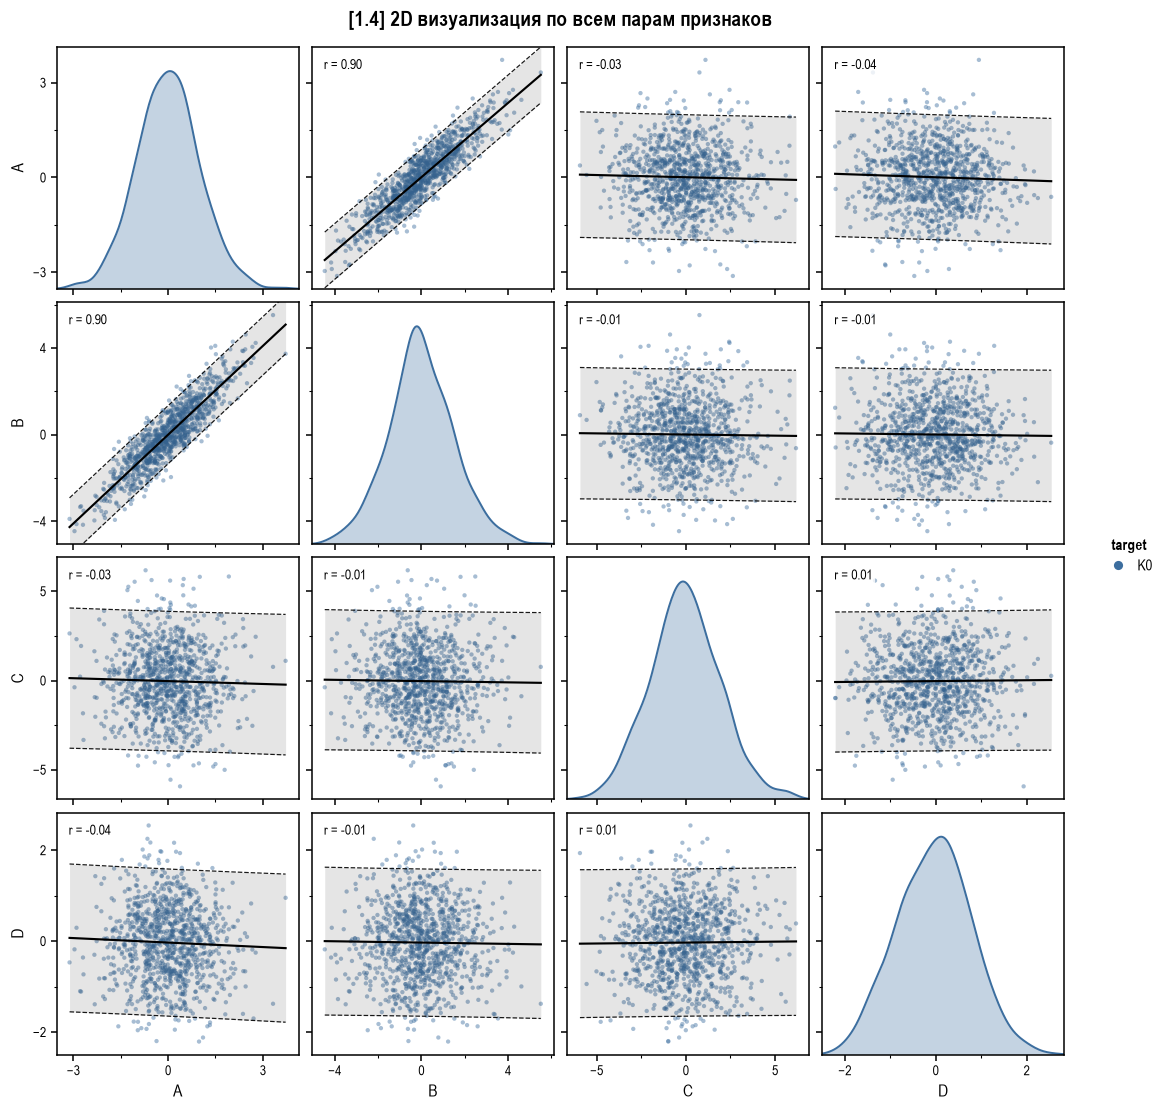

In [8]:
res = scatter_matrix(dfS00, FEATURES, CLASS_COL, style=SCATTER)
res.savefig(FIG / "1.4_scatter_matrix.png")
plt.show()

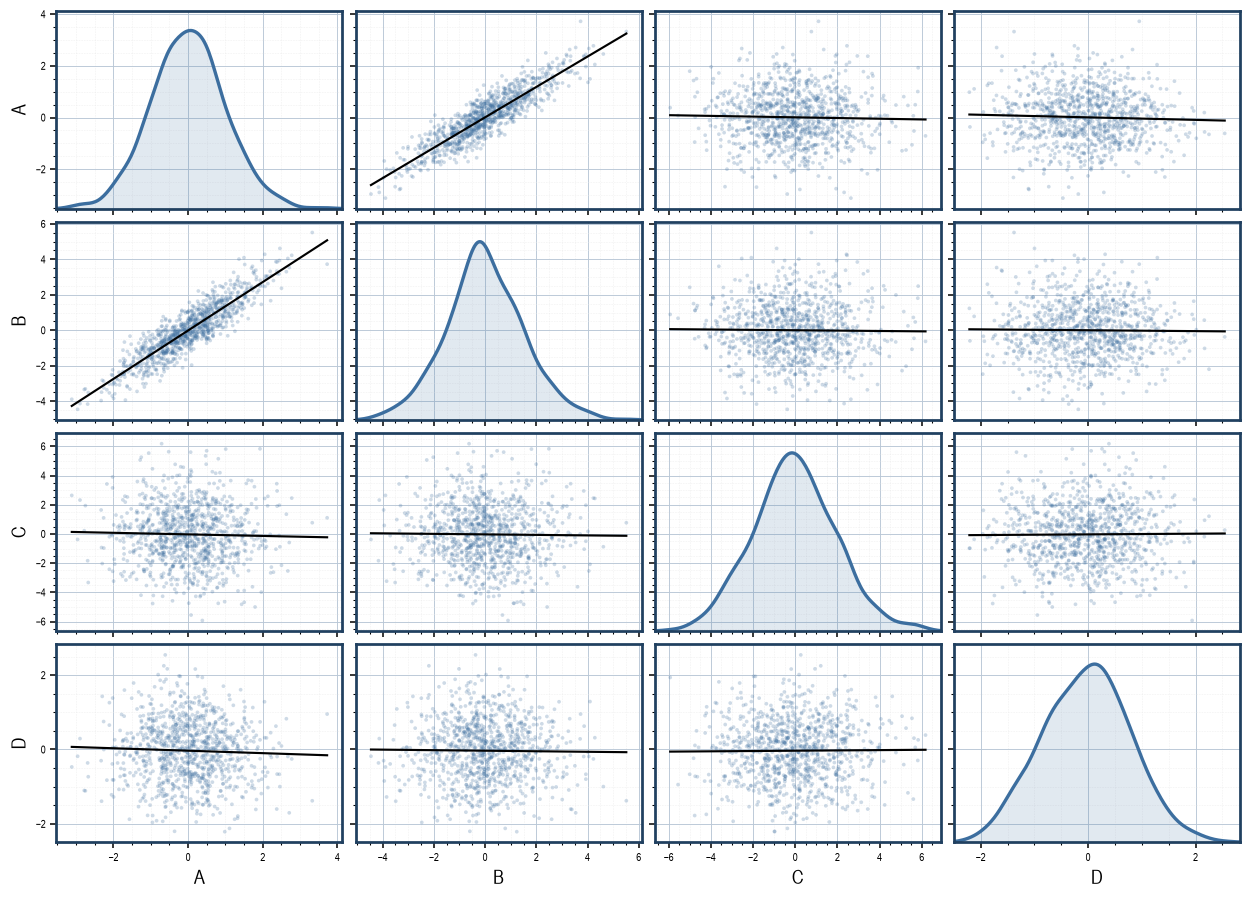

In [9]:
# Тот же вызов с другими параметрами: цветные толстые оси, шаг рисок вместо их
# числа, большая и малая сетка, неквадратные панели, другие размеры шрифтов,
# прозрачнее точки, легенда и заглавие выключены.
loud = SCATTER.derive(
    spine_color="#204060", spine_width=1.8,
    grid_major_shown=True, grid_minor_shown=True, grid_major_color="#B9C7D6",
    panel_width=2.6, panel_height=1.8,
    points_size=6.0, points_alpha=0.25,
    diagonal_kde_fill_alpha=0.15, diagonal_kde_line_width=2.2,
    tick_labels_x_font_size=7, tick_labels_y_font_size=7,
    axis_labels_x_font_size=13, axis_labels_y_font_size=13,
    regression_line_predict_bands_shown=False, annotation_shown=False,
    legend_shown=False, title_shown=False,
)
res = set_tick_step(scatter_matrix(dfS00, FEATURES, CLASS_COL, style=loud), major=2.0, minor=0.5)
res.savefig(FIG / "1.4_scatter_matrix_restyled.png")
plt.show()

## [1.5] Heatmap корреляций: Пирсон и Спирмен

Пирсон измеряет линейную связь, Спирмен — монотонную (на рангах). На нормальных
данных без выбросов они должны почти совпасть; расхождение между ними позже
станет индикатором того, что заполнение пропусков исказило форму облака.

Цветовая шкала расходящаяся и жёстко закреплена на `[-1, 1]` с нулём по центру,
поэтому любые две картинки в задании сравнимы напрямую.

Разрез «в каждом отдельном классе» строится, но класс один, поэтому панель
`класс K0` совпадает с панелью «весь датасет».

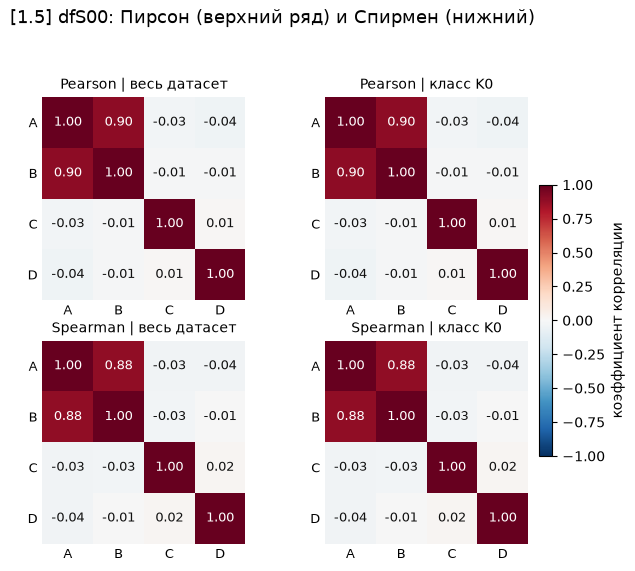

In [10]:
corr_S00 = correlation_tables(dfS00, FEATURES, CLASS_COL, per_class=True)
# упорядочиваем панели по методу, затем по разрезу: верхний ряд — Пирсон, нижний — Спирмен
corr_S00 = {k: corr_S00[k] for k in sorted(corr_S00, key=lambda k: (k[1], k[0]))}
fig = plot_correlation_heatmaps(
    corr_S00, ncols=2, suptitle="[1.5] dfS00: Пирсон (верхний ряд) и Спирмен (нижний)",
)
fig.savefig(FIG / "1.5_corr_dfS00.png", bbox_inches="tight", dpi=120)
plt.show()

In [11]:
display(Markdown("**Пирсон минус Спирмен на всём датасете** (мера нелинейности связи):"))
display((corr_S00[("весь датасет", "pearson")] - corr_S00[("весь датасет", "spearman")]).round(3))

**Пирсон минус Спирмен на всём датасете** (мера нелинейности связи):

,A,B,C,D
A,0.000,0.011,0.005,-0.003
B,0.011,0.000,0.013,-0.008
C,0.005,0.013,0.000,-0.006
D,-0.003,-0.008,-0.006,0.000


## [1.6] Клонирование с пропусками: `dfSdXX`

Удаление **MCAR** (completely at random): вероятность пропуска не зависит ни от
самого значения, ни от остальных признаков. Число удаляемых ячеек считается
точно (`round(share * n_cells)`), а не бросанием монетки на каждую ячейку, —
иначе «5%» превращались бы в 5% ± шум.

Класс не портим: удаляются только ячейки признаков.

In [12]:
families = make_mcar_family(dfS00, SHARES, FEATURES, random_state=RANDOM_STATE)

overview = pd.DataFrame({
    name: {
        "удалено ячеек, %": round(d[FEATURES].isna().to_numpy().mean() * 100, 2),
        "строк без пропусков": int(d[FEATURES].notna().all(axis=1).sum()),
        "строк целиком пустых": int(d[FEATURES].isna().all(axis=1).sum()),
        f"пар {PAIR_1[0]}+{PAIR_1[1]}": int(d[list(PAIR_1)].notna().all(axis=1).sum()),
        f"r{PAIR_1}": round(d[PAIR_1[0]].corr(d[PAIR_1[1]]), 3),
    }
    for name, d in families.items()
}).T
overview

,"удалено ячеек, %",строк без пропусков,строк целиком пустых,пар A+B,"r('A', 'B')"
dfSd00,0.0,1000.0,0.0,1000.0,0.896
dfSd01,1.0,960.0,0.0,981.0,0.894
dfSd02,2.0,924.0,0.0,958.0,0.896
dfSd05,5.0,810.0,0.0,905.0,0.898
dfSd10,10.0,663.0,0.0,817.0,0.897
dfSd20,20.0,418.0,0.0,648.0,0.890
dfSd50,50.0,73.0,70.0,252.0,0.894
dfSd80,80.0,2.0,424.0,48.0,0.910


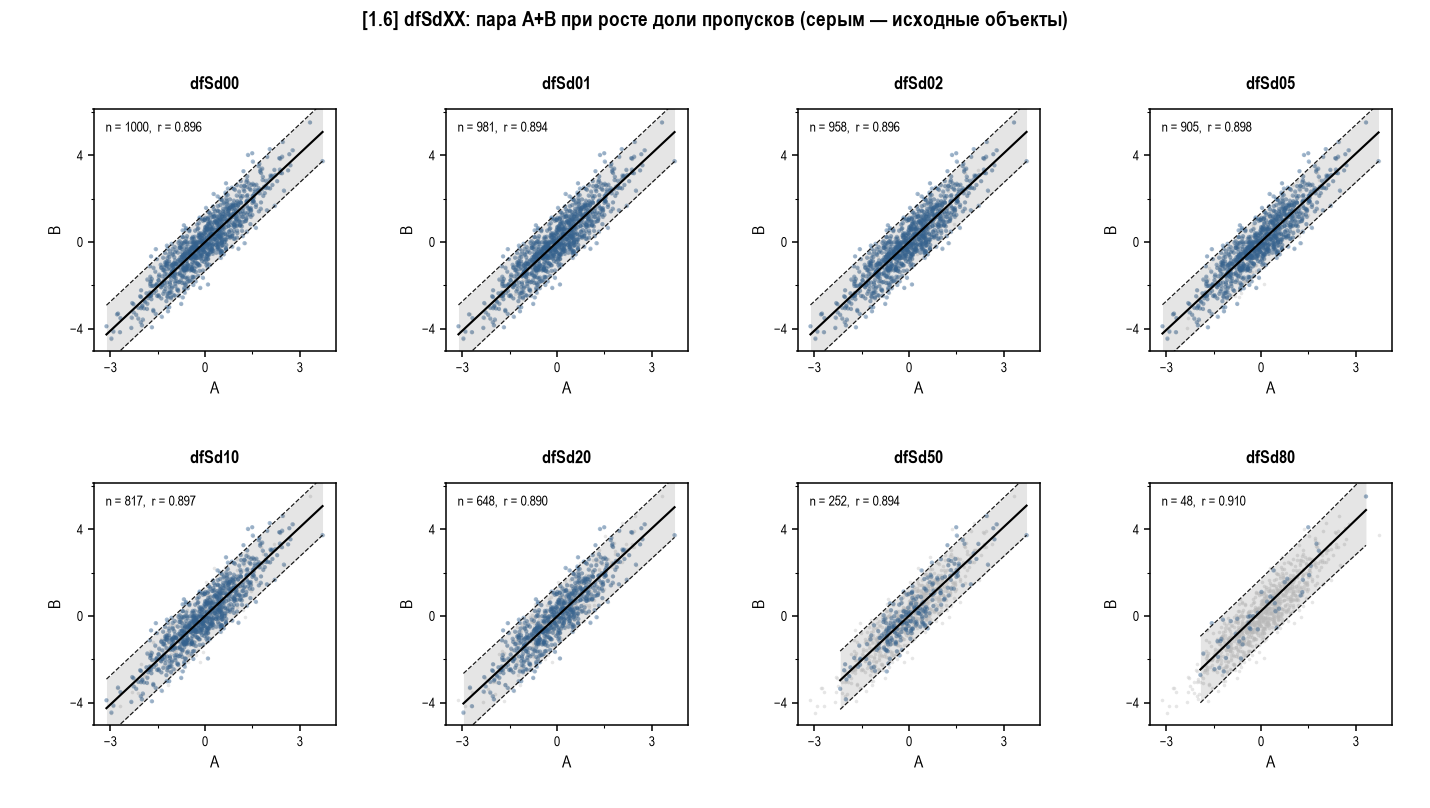

In [13]:
fig = scatter_panel(
    families, PAIR_1, CLASS_COL, style=SCATTER, ncols=PANEL_NCOLS,
    reference=dfS00, share_limits=True,
    suptitle=f"[1.6] dfSdXX: пара {PAIR_1[0]}+{PAIR_1[1]} при росте доли пропусков "
             f"(серым — исходные объекты)",
)
fig.savefig(FIG / "1.6_panel_dfSdXX.png", bbox_inches="tight", dpi=120)
plt.show()

Видно главное свойство MCAR: облако **редеет, но не деформируется**. Оценка
`r(A,B)` держится около 0.9 вплоть до 50% удалённых ячеек — просто потому, что
она считается по парам, где оба значения выжили, а такая подвыборка остаётся
представительной. При 80% пар остаётся уже несколько десятков, и оценка начинает
заметно «плавать».

## [1.7] Заполнение медианой: `dfSdXXmed`

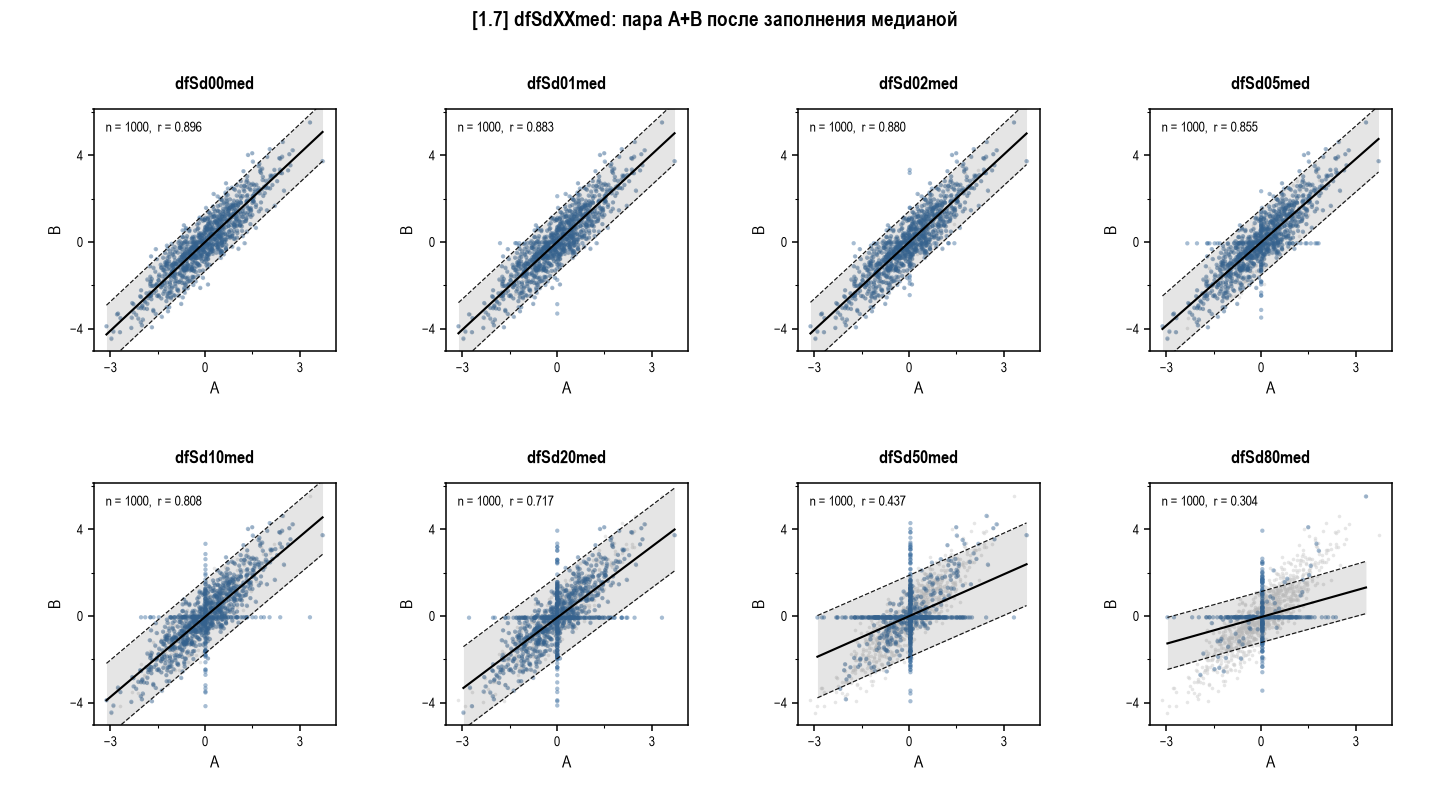

In [14]:
medians = median_family(families, FEATURES, CLASS_COL)

fig = scatter_panel(
    medians, PAIR_1, CLASS_COL, style=SCATTER, ncols=PANEL_NCOLS,
    reference=dfS00, share_limits=True,
    suptitle=f"[1.7] dfSdXXmed: пара {PAIR_1[0]}+{PAIR_1[1]} после заполнения медианой",
)
fig.savefig(FIG / "1.7_panel_dfSdXXmed.png", bbox_inches="tight", dpi=120)
plt.show()

Характерный «крест» — прямой результат заполнения константой: все объекты с
пропавшим `A` встают на одну вертикаль (медиана `A`), с пропавшим `B` — на одну
горизонталь, а те, где пропали оба, собираются в одну точку в центре. Чем больше
доля пропусков, тем плотнее крест и тем сильнее он тянет корреляцию к нулю.

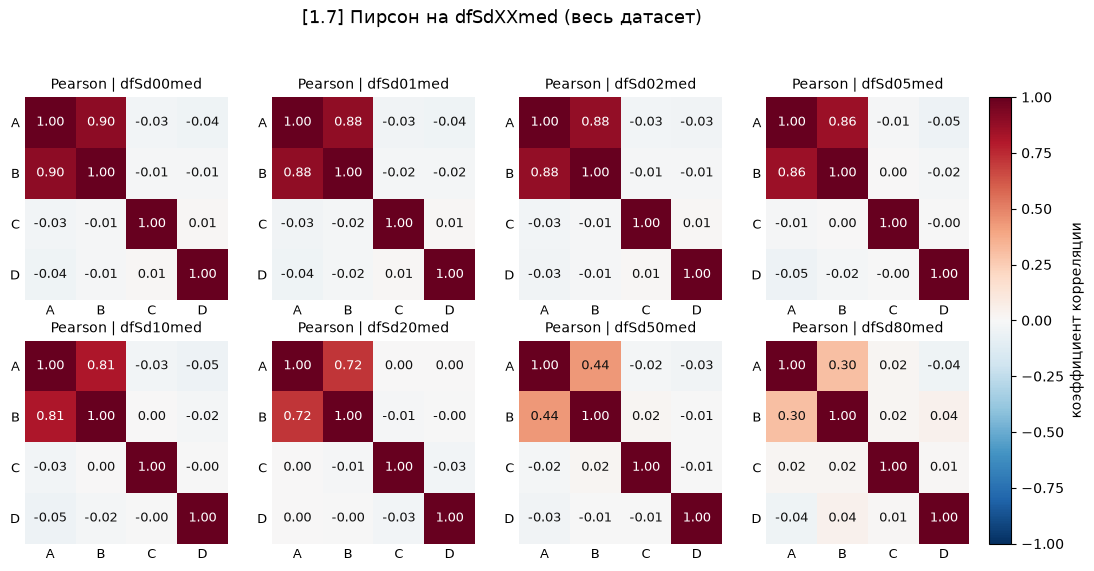

In [15]:
# Пирсон на всём датасете для всех dfSdXXmed — панели сравнимы между собой
pearson_med = {
    (name, "pearson"): d[FEATURES].corr()
    for name, d in medians.items()
}
fig = plot_correlation_heatmaps(
    pearson_med, ncols=PANEL_NCOLS,
    suptitle="[1.7] Пирсон на dfSdXXmed (весь датасет)",
)
fig.savefig(FIG / "1.7_corr_dfSdXXmed.png", bbox_inches="tight", dpi=120)
plt.show()

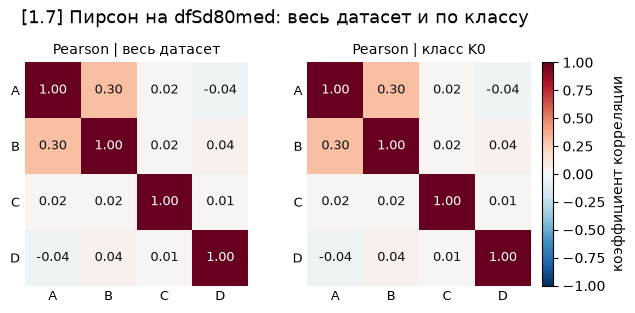

,"r('A', 'B')",r до заполнения
dfSd00med,0.896,0.896
dfSd01med,0.883,0.894
dfSd02med,0.880,0.896
dfSd05med,0.855,0.898
dfSd10med,0.808,0.897
dfSd20med,0.717,0.890
dfSd50med,0.437,0.894
dfSd80med,0.304,0.910


In [16]:
# Тот же разрез «как в [1.5]», но по классам — на самом разрушенном датасете
worst = f"dfSd{round(max(SHARES) * 100):02d}med"
fig = plot_correlation_heatmaps(
    correlation_tables(medians[worst], FEATURES, CLASS_COL, methods=("pearson",)),
    ncols=2, suptitle=f"[1.7] Пирсон на {worst}: весь датасет и по классу",
)
fig.savefig(FIG / f"1.7_corr_{worst}_by_class.png", bbox_inches="tight", dpi=120)
plt.show()

decay = pd.DataFrame({
    name: {f"r{PAIR_1}": round(d[PAIR_1[0]].corr(d[PAIR_1[1]]), 3)}
    for name, d in medians.items()
}).T
decay["r до заполнения"] = [round(families[n[:-3]][PAIR_1[0]].corr(
    families[n[:-3]][PAIR_1[1]]), 3) for n in decay.index]
decay

Вот оно, численно: до заполнения `r` держится около 0.9, после заполнения
медианой — обваливается пропорционально доле пропусков. Заполнение константой
не «восстанавливает» данные, а **добавляет массу в центре**, разбавляя связь.

## [1.8] Четыре метода заполнения на выбранном `dfSdXX`

| Метод | Что делает |
|---|---|
| `med` | каждый пропуск → медиана своего столбца; связи между признаками игнорируются |
| `knn` | среднее по 5 ближайшим соседям, расстояние считается по наблюдённым координатам |
| `reg` | один детерминированный проход: признак регрессируется на остальные |
| `mice` | chained equations: много проходов, значение берётся из апостериорного распределения |

`reg` и `mice` отличаются именно этим: первый ставит в пропуск условное
ожидание (и потому **занижает** дисперсию и **завышает** корреляцию), второй
добавляет шум нужного масштаба и сохраняет разброс.

In [17]:
chosen = families[CHOSEN]
imputed = impute_family(chosen, METHODS, FEATURES, CLASS_COL, random_state=RANDOM_STATE)
imputed = {f"{CHOSEN}{name}": frame for name, frame in imputed.items()}

stage = {"dfSd00": dfS00, CHOSEN: chosen, **imputed}
print("Датасеты пункта [1.8]:", ", ".join(stage))

errors = pd.DataFrame({
    name: imputation_error(dfS00, frame, chosen, FEATURES)
    for name, frame in imputed.items()
}).T
errors.index = [f"{i}  ({RU_NAMES[i.replace(CHOSEN, '')]})" for i in errors.index]
display(Markdown(f"**Ошибка восстановления на скрытых ячейках ({CHOSEN}):**"))
display(errors.round(3))

Датасеты пункта [1.8]: dfSd00, dfSd20, dfSd20med, dfSd20knn, dfSd20reg, dfSd20mice


**Ошибка восстановления на скрытых ячейках (dfSd20):**

,RMSE,MAE,n_filled
dfSd20med (медиана),1.361,1.001,800.0
dfSd20knn (kNN),1.483,1.081,800.0
dfSd20reg (регрессия),1.147,0.800,800.0
dfSd20mice (MICE),1.763,1.221,800.0


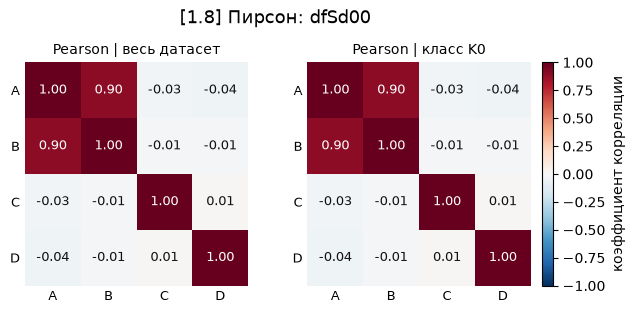

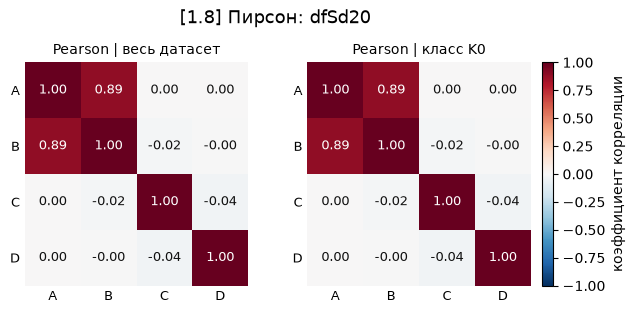

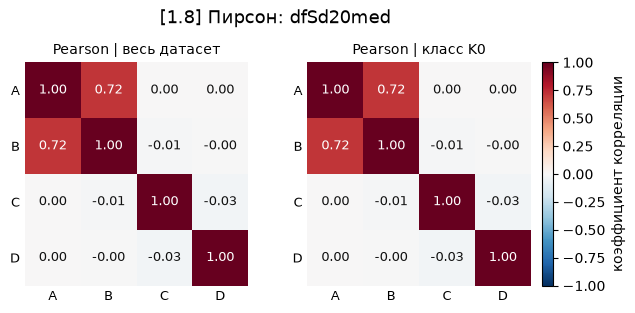

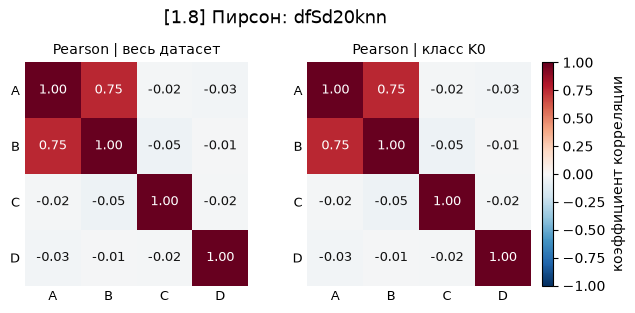

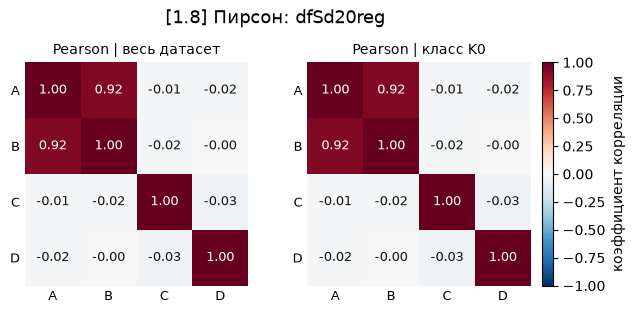

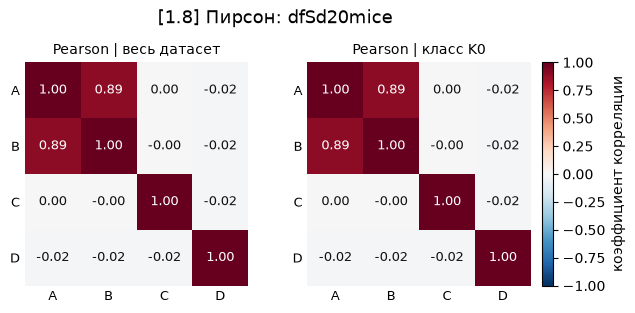

In [18]:
# Heatmap Пирсона «как в [1.5]»: весь датасет и каждый класс, для каждого датасета
for name, frame in stage.items():
    fig = plot_correlation_heatmaps(
        correlation_tables(frame, FEATURES, CLASS_COL, methods=("pearson",)),
        ncols=2, suptitle=f"[1.8] Пирсон: {name}",
    )
    fig.savefig(FIG / f"1.8_corr_{name}.png", bbox_inches="tight", dpi=120)
plt.show()

In [19]:
summary = pd.DataFrame({
    name: {
        f"r{PAIR_1}": round(frame[PAIR_1[0]].corr(frame[PAIR_1[1]]), 3),
        f"r{PAIR_2}": round(frame[PAIR_2[0]].corr(frame[PAIR_2[1]]), 3),
        f"std {PAIR_1[0]}": round(frame[PAIR_1[0]].std(), 3),
        f"std {PAIR_1[1]}": round(frame[PAIR_1[1]].std(), 3),
    }
    for name, frame in stage.items()
}).T
display(Markdown(f"**Что стало со связями (эталон — `dfSd00`, заказано "
                 f"r{PAIR_1}={spec.corr}, r{PAIR_2}=0):**"))
display(summary)

**Что стало со связями (эталон — `dfSd00`, заказано r('A', 'B')=0.9, r('C', 'D')=0):**

,"r('A', 'B')","r('C', 'D')",std A,std B
dfSd00,0.896,0.010,0.989,1.507
dfSd20,0.890,-0.039,0.991,1.512
dfSd20med,0.717,-0.030,0.888,1.356
dfSd20knn,0.752,-0.023,0.930,1.415
dfSd20reg,0.922,-0.032,0.961,1.455
dfSd20mice,0.892,-0.023,0.990,1.512


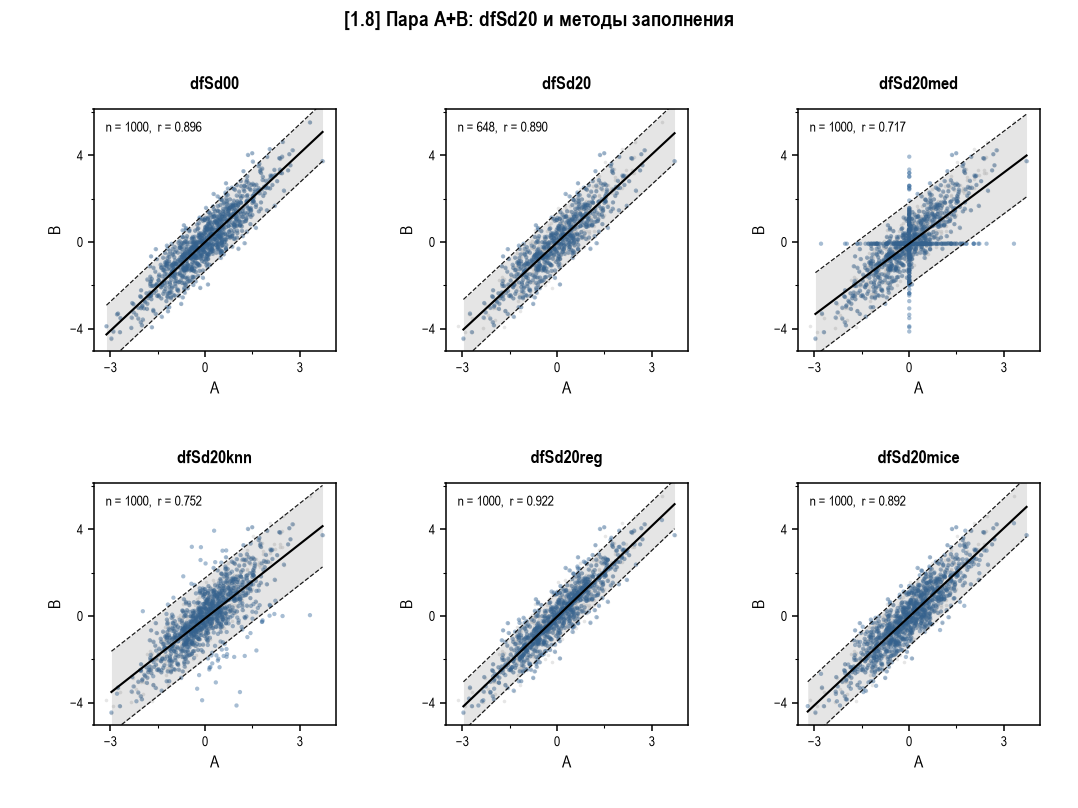

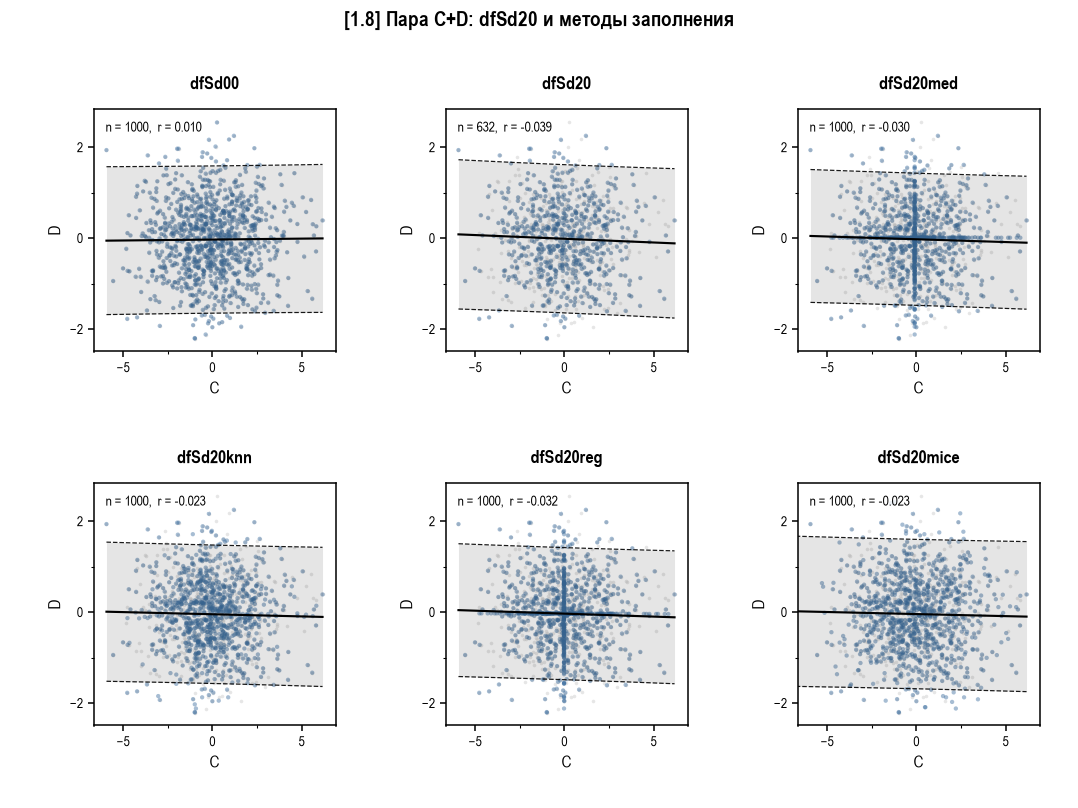

In [20]:
for pair, tag in ((PAIR_1, "pair1"), (PAIR_2, "pair2")):
    fig = scatter_panel(
        stage, pair, CLASS_COL, style=SCATTER, ncols=3,
        reference=dfS00, share_limits=True,
        suptitle=f"[1.8] Пара {pair[0]}+{pair[1]}: {CHOSEN} и методы заполнения",
    )
    fig.savefig(FIG / f"1.8_panel_{tag}.png", bbox_inches="tight", dpi=120)
plt.show()

## [1.9] UpSet plot — через собственный модуль `upsetkit`

Два вопроса из условия и как они ложатся на UpSet:

**(а) числа объектов с пропущенными значениями для всех вариантов группировки
пропусков по признакам.** Условие на признак — «значение отсутствует»;
пересечения перечисляют все комбинации признаков, пропавших вместе.

**(б) числа объектов с совпадающими значениями по признакам.** Условие на
признак — «значение этого объекта совпадает со значением другого объекта по этому
же признаку». На непрерывных данных совпадений не бывает вовсе — зато они
массово появляются там, где заполнитель вписал константу. Поэтому (б) работает
как **отпечаток метода заполнения**: медиана вписывает одну и ту же константу и
потому даёт группу совпадений в каждом испорченном столбце, а kNN, регрессия и
MICE считают для каждой ячейки своё значение и не дают ни одного совпадения.

Альтернативное чтение (б) — «совпадение внутри пары признаков», по одному
условию на пару `A=B`, `A=C`, …; для непрерывных величин оно требует допуска
`atol`, иначе всегда пусто. Оба варианта есть в `t1lib/upsetviews.py`.

Оба вида строятся вызовом `plot_upset(...)` из `upsetkit`.

### (а) Пропуски по признакам, датасеты пункта [1.8]

  [внимание] dfSd00 — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd00 — пропуски по признакам: ни одно условие не выполняется.
  [внимание] dfSd20med — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd20med — пропуски по признакам: ни одно условие не выполняется.
  [внимание] dfSd20knn — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd20knn — пропуски по признакам: ни одно условие не выполняется.
  [внимание] dfSd20reg — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd20reg — пропуски по признакам: ни одно условие не выполняется.
  [внимание] dfSd20mice — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd20mice — пропуски по признакам: ни одно условие не выполняется.


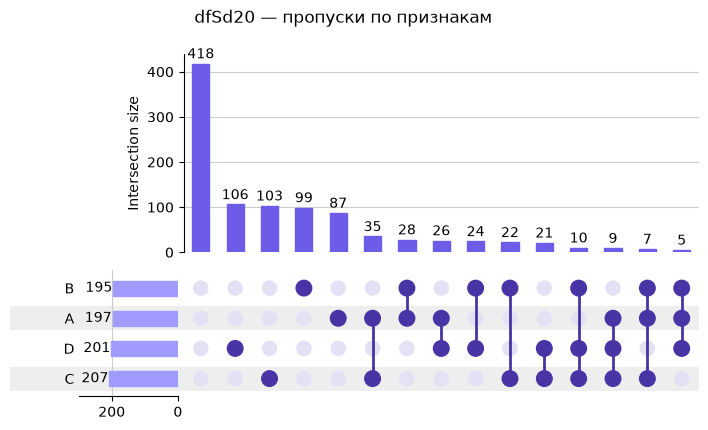

In [21]:
display(Markdown("### (а) Пропуски по признакам, датасеты пункта [1.8]"))
res_missing = upset_series(stage, FEATURES, kind="missing", outdir=str(FIG),
                           prefix="1.9a")
plt.show()

Заполненные датасеты сюда не попадают по построению: после импутации пропусков
не осталось, а `dfSd00` их и не имел — модуль сообщает об этом вместо того, чтобы
рисовать пустую матрицу. Содержательная картинка здесь одна, по самому `dfSdXX`.

Поэтому ниже тот же разрез (а) прогоняется по всему семейству `dfSdXX` из [1.6] —
именно там UpSet показывает, как с ростом доли пропусков центр тяжести уезжает от
«ничего не пропало» к «пропало всё сразу».

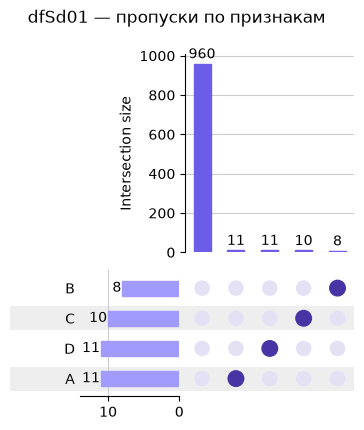

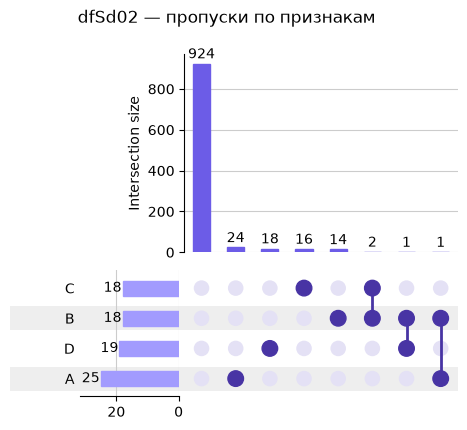

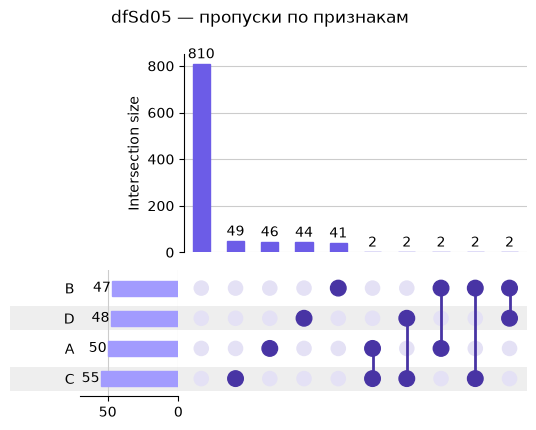

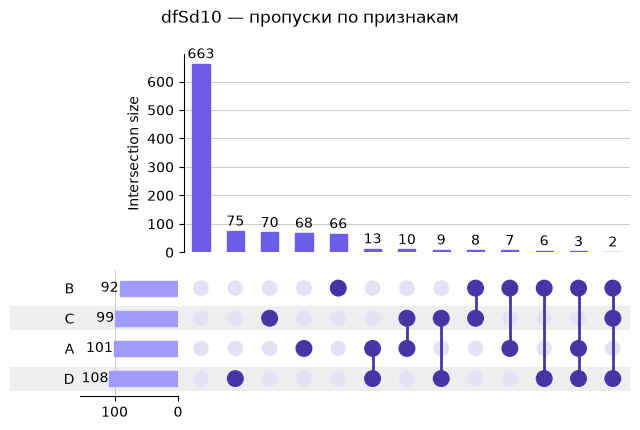

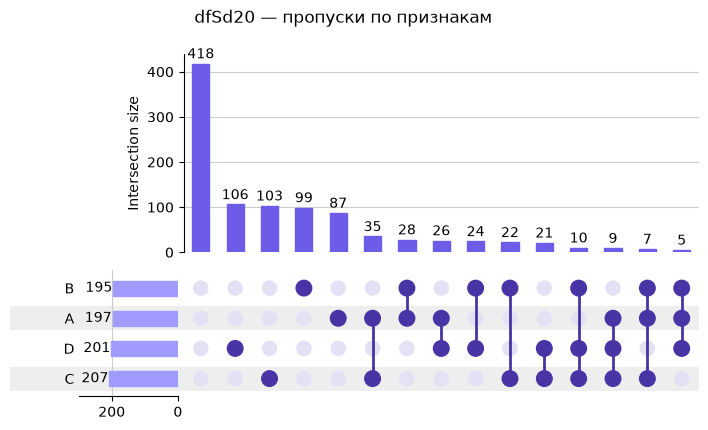

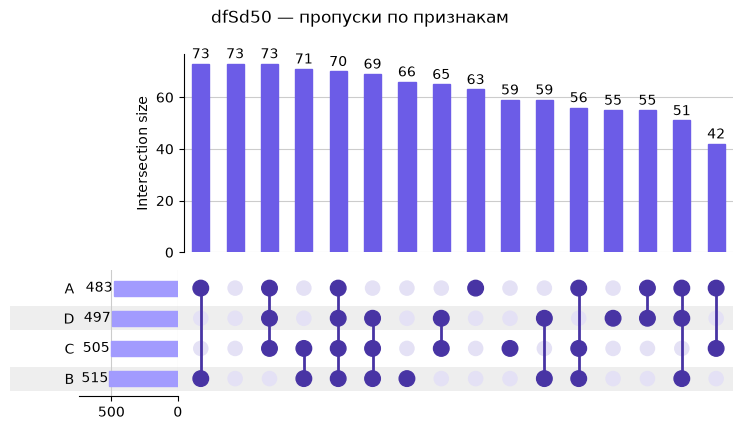

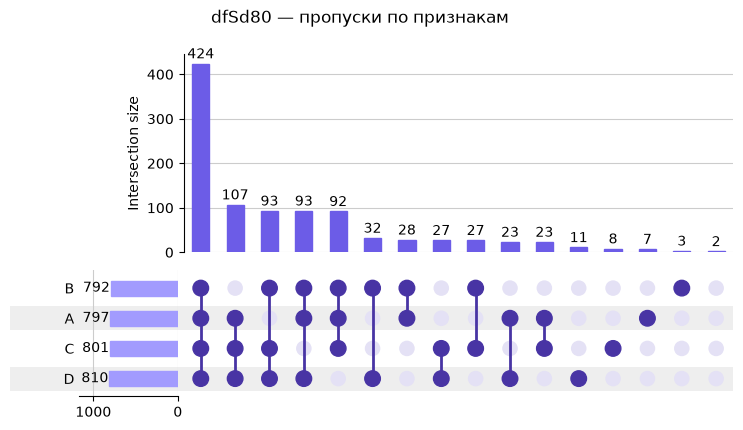

In [22]:
res_missing_family = upset_series(
    {k: v for k, v in families.items() if v[FEATURES].isna().to_numpy().any()},
    FEATURES, kind="missing", outdir=str(FIG), prefix="1.9a_family",
)
plt.show()

In [23]:
display(Markdown("**Размеры пересечений по семейству `dfSdXX`** "
                 "(«—» = ни одного пропуска в строке):"))
display(intersections_table(res_missing_family, top=16))

**Размеры пересечений по семейству `dfSdXX`** («—» = ни одного пропуска в строке):

,dfSd01,dfSd02,dfSd05,dfSd10,dfSd20,dfSd50,dfSd80
—,960,924,810,663,418,73,2
D+C+A+B,0,0,0,0,0,0,424
D+C+A,0,0,0,0,0,0,107
D,11,18,44,75,106,55,11
C,10,16,49,70,103,59,8
B,8,14,41,66,99,66,3
D+C+B,0,0,0,2,0,0,93
D+A+B,0,0,0,3,5,0,93
C+A+B,0,0,0,0,7,0,92
A,11,24,46,68,87,63,7


### (б) Совпадающие значения по признакам

  [внимание] dfSd00 — совпадающие значения по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd00 — совпадающие значения по признакам: ни одно условие не выполняется.
  [внимание] dfSd20 — совпадающие значения по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd20 — совпадающие значения по признакам: ни одно условие не выполняется.
  [внимание] dfSd20knn — совпадающие значения по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd20knn — совпадающие значения по признакам: ни одно условие не выполняется.
  [внимание] dfSd20reg — совпадающие значения по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd20reg — совпадающие значения по признакам: ни одно условие не выполняется.
  [внимание] dfSd20mice — совпадающие значения по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [п

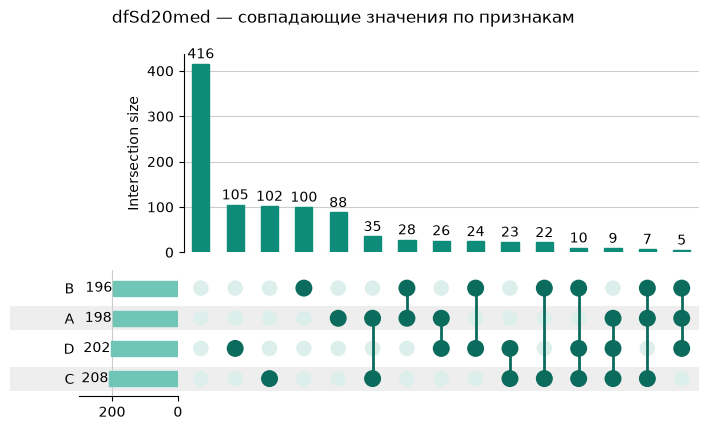

In [24]:
display(Markdown("### (б) Совпадающие значения по признакам"))
res_dup = upset_series(stage, FEATURES, kind="duplicated", outdir=str(FIG),
                       prefix="1.9b")
plt.show()

**Объекты с совпадающими значениями:**

,dfSd20med
—,416
D,105
C,102
B,100
A,88
C+A,35
A+B,28
D+A,26
D+B,24
C+D,23


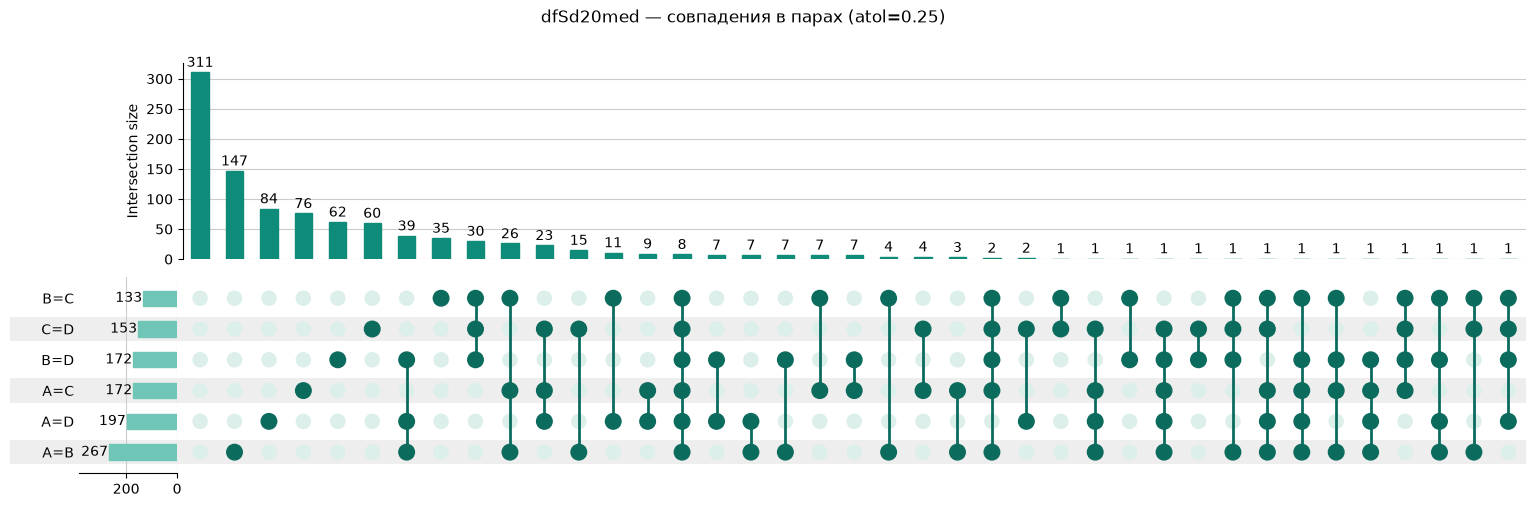

In [25]:
if res_dup:
    display(Markdown("**Объекты с совпадающими значениями:**"))
    display(intersections_table(res_dup, top=16))

# Альтернативное чтение (б): совпадение внутри пары признаков, с допуском.
alt = upset_pairwise_equal(imputed[f"{CHOSEN}med"], FEATURES,
                           title=f"{CHOSEN}med — совпадения в парах (atol=0.25)",
                           atol=0.25)
if alt is not None:
    alt.figure.savefig(FIG / "1.9b_pairwise_med.png", bbox_inches="tight", dpi=120)
plt.show()

## [1.10]** `dfMNAR`: пропуски, зависящие от самих значений

Из `C` и `D` удаляется всё, что **ниже медианы признака**. Это MNAR: механизм
пропуска знает значение, которое он прячет. Ровно половина каждого из двух
столбцов исчезает, и исчезает не случайная половина, а нижняя.

Следствие, которое видно уже без вычислений: любой метод, обучающийся на
наблюдённых данных, видит только верхние половины `C` и `D` и не может знать,
что было ниже. Средние по этим столбцам завышены, разброс занижен, и никакая
импутация этого не исправит — она лишь по-разному замаскирует.

In [26]:
dfMNAR = make_mnar_below_median(dfS00, features=PAIR_2, quantile=0.5)

display(pd.DataFrame({
    "пропусков, %": (dfMNAR[FEATURES].isna().mean() * 100).round(1),
    "mean наблюдённых": dfMNAR[FEATURES].mean().round(3),
    "mean истинных": dfS00[FEATURES].mean().round(3),
    "std наблюдённых": dfMNAR[FEATURES].std().round(3),
    "std истинных": dfS00[FEATURES].std().round(3),
}))
print("Строк без пропусков:", int(dfMNAR[FEATURES].notna().all(axis=1).sum()), "из", len(dfMNAR))

,"пропусков, %",mean наблюдённых,mean истинных,std наблюдённых,std истинных
A,0.0,0.009,0.009,0.989,0.989
B,0.0,0.003,0.003,1.507,1.507
C,50.0,1.505,-0.032,1.253,1.953
D,50.0,0.618,-0.033,0.475,0.809


Строк без пропусков: 250 из 1000


In [27]:
# [1.8] для dfMNAR
imputed_mnar = impute_family(dfMNAR, METHODS, FEATURES, CLASS_COL, random_state=RANDOM_STATE)
imputed_mnar = {f"dfMNAR{name}": frame for name, frame in imputed_mnar.items()}
stage_mnar = {"dfSd00": dfS00, "dfMNAR": dfMNAR, **imputed_mnar}

errors_mnar = pd.DataFrame({
    name: imputation_error(dfS00, frame, dfMNAR, FEATURES)
    for name, frame in imputed_mnar.items()
}).T
display(Markdown("**Ошибка восстановления на скрытых ячейках (`dfMNAR`):**"))
display(errors_mnar.round(3))

display(pd.DataFrame({
    name: {
        f"r{PAIR_1}": round(frame[PAIR_1[0]].corr(frame[PAIR_1[1]]), 3),
        f"r{PAIR_2}": round(frame[PAIR_2[0]].corr(frame[PAIR_2[1]]), 3),
        f"mean {PAIR_2[0]}": round(frame[PAIR_2[0]].mean(), 3),
        f"std {PAIR_2[0]}": round(frame[PAIR_2[0]].std(), 3),
    }
    for name, frame in stage_mnar.items()
}).T)

**Ошибка восстановления на скрытых ячейках (`dfMNAR`):**

,RMSE,MAE,n_filled
dfMNARmed,2.326,1.997,1000.0
dfMNARknn,2.576,2.194,1000.0
dfMNARreg,2.521,2.188,1000.0
dfMNARmice,2.696,2.212,1000.0


,"r('A', 'B')","r('C', 'D')",mean C,std C
dfSd00,0.896,0.010,-0.032,1.953
dfMNAR,0.896,-0.019,1.505,1.253
dfMNARmed,0.896,-0.004,1.367,0.896
dfMNARknn,0.896,-0.024,1.518,0.999
dfMNARreg,0.896,-0.011,1.505,0.886
dfMNARmice,0.896,-0.035,1.500,1.281


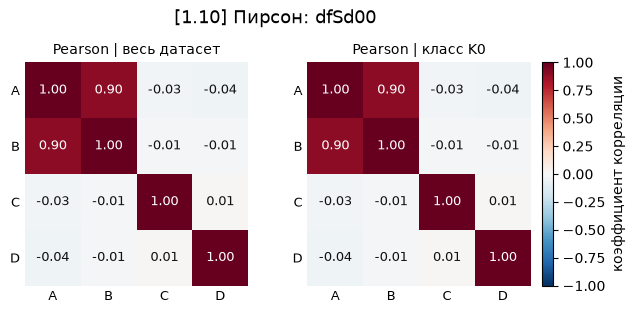

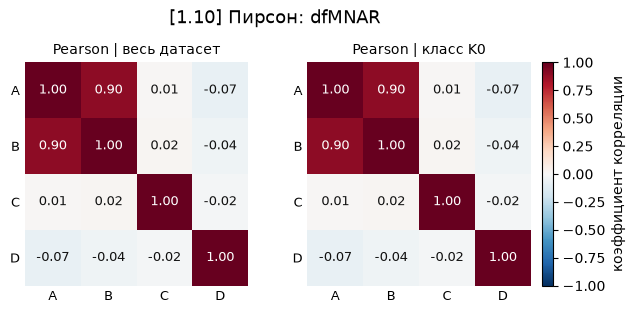

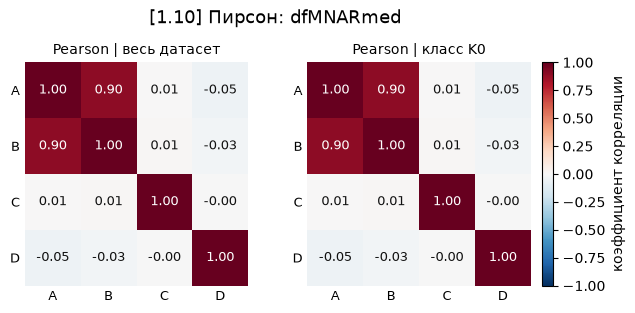

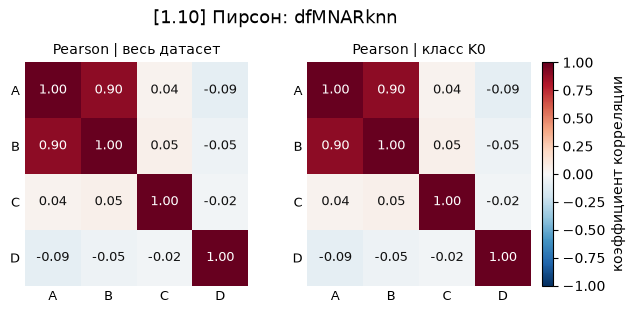

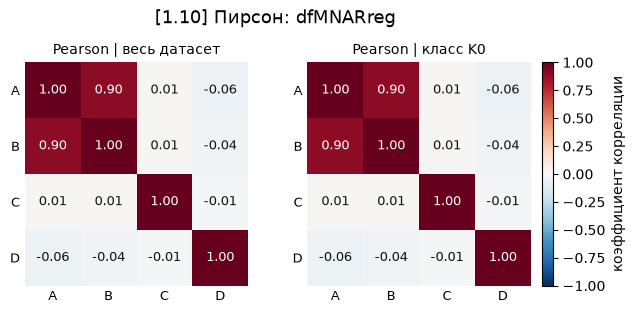

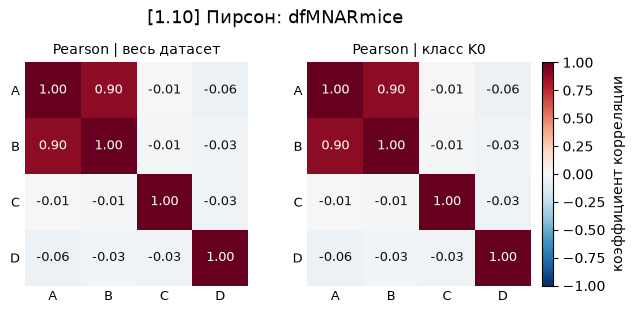

In [28]:
for name, frame in stage_mnar.items():
    fig = plot_correlation_heatmaps(
        correlation_tables(frame, FEATURES, CLASS_COL, methods=("pearson",)),
        ncols=2, suptitle=f"[1.10] Пирсон: {name}",
    )
    fig.savefig(FIG / f"1.10_corr_{name}.png", bbox_inches="tight", dpi=120)
plt.show()

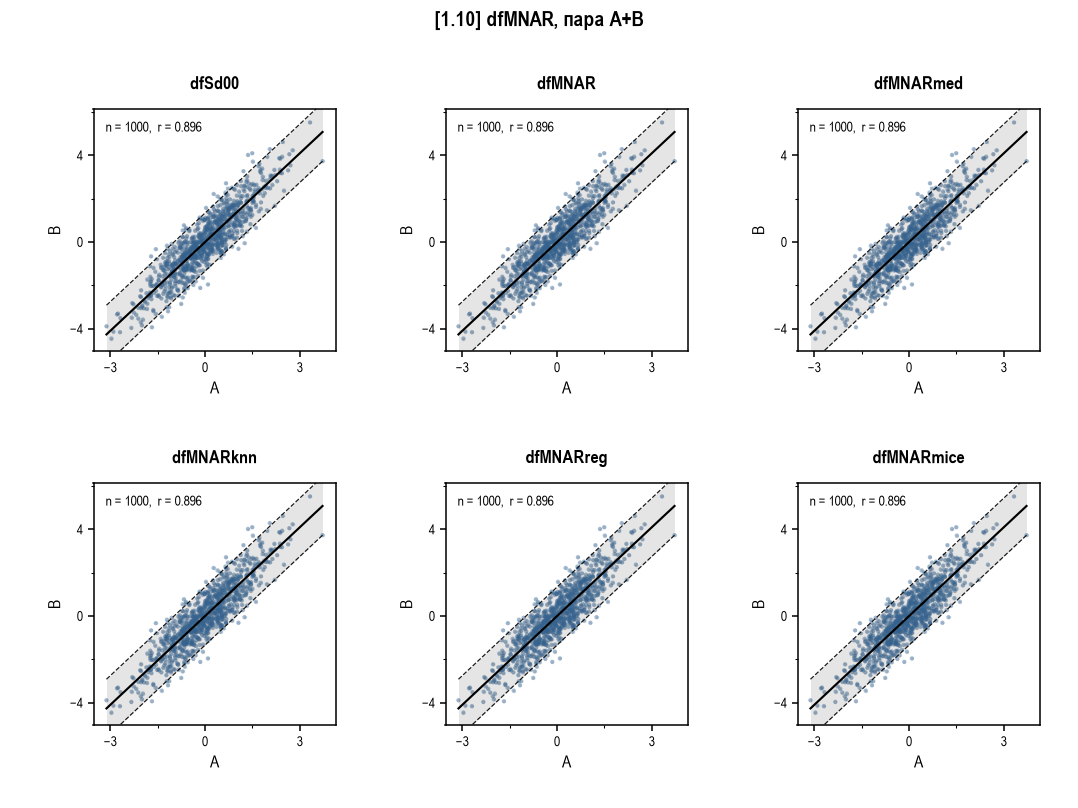

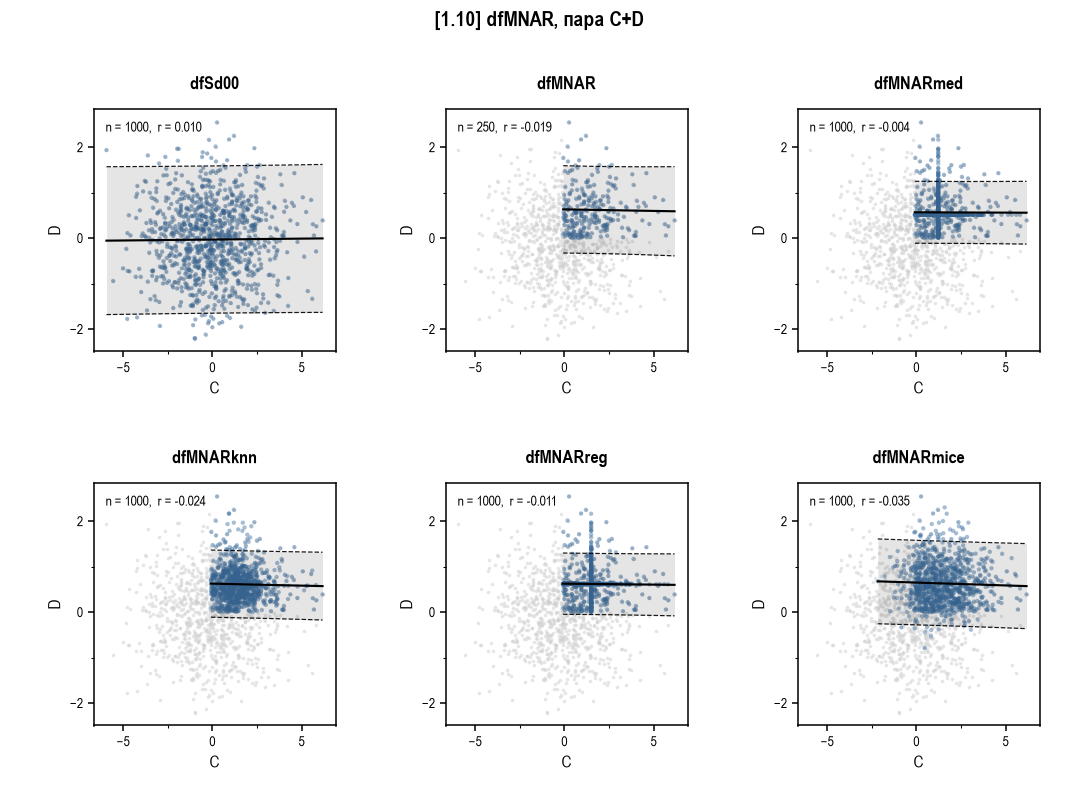

In [29]:
for pair, tag in ((PAIR_1, "pair1"), (PAIR_2, "pair2")):
    fig = scatter_panel(
        stage_mnar, pair, CLASS_COL, style=SCATTER, ncols=3,
        reference=dfS00, share_limits=True,
        suptitle=f"[1.10] dfMNAR, пара {pair[0]}+{pair[1]}",
    )
    fig.savefig(FIG / f"1.10_panel_{tag}.png", bbox_inches="tight", dpi=120)
plt.show()

### [1.10] → [1.9](а) Пропуски по признакам

  [внимание] dfSd00 — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd00 — пропуски по признакам: ни одно условие не выполняется.
  [внимание] dfMNAR — пропуски по признакам: условия без единого объекта (A, B) — upsetplot их не рисует.


  [внимание] dfMNARmed — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfMNARmed — пропуски по признакам: ни одно условие не выполняется.
  [внимание] dfMNARknn — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfMNARknn — пропуски по признакам: ни одно условие не выполняется.
  [внимание] dfMNARreg — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfMNARreg — пропуски по признакам: ни одно условие не выполняется.
  [внимание] dfMNARmice — пропуски по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfMNARmice — пропуски по признакам: ни одно условие не выполняется.


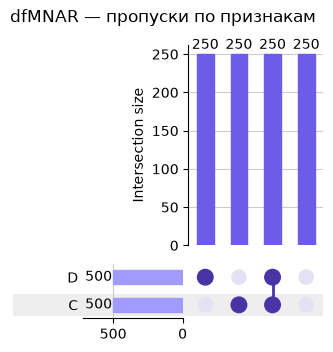

In [30]:
# [1.9] для dfMNAR
display(Markdown("### [1.10] → [1.9](а) Пропуски по признакам"))
res_mnar_missing = upset_series(stage_mnar, FEATURES, kind="missing",
                               outdir=str(FIG), prefix="1.10a")
plt.show()

### [1.10] → [1.9](б) Совпадающие значения по признакам

  [внимание] dfSd00 — совпадающие значения по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfSd00 — совпадающие значения по признакам: ни одно условие не выполняется.
  [внимание] dfMNAR — совпадающие значения по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfMNAR — совпадающие значения по признакам: ни одно условие не выполняется.
  [внимание] dfMNARmed — совпадающие значения по признакам: условия без единого объекта (A, B) — upsetplot их не рисует.
  [внимание] dfMNARknn — совпадающие значения по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfMNARknn — совпадающие значения по признакам: ни одно условие не выполняется.
  [внимание] dfMNARreg — совпадающие значения по признакам: условия без единого объекта (A, B, C, D) — upsetplot их не рисует.
  [пропущено] dfMNARreg — совпадающие значения по признакам: ни одно условие не выполняется.
  [внимание

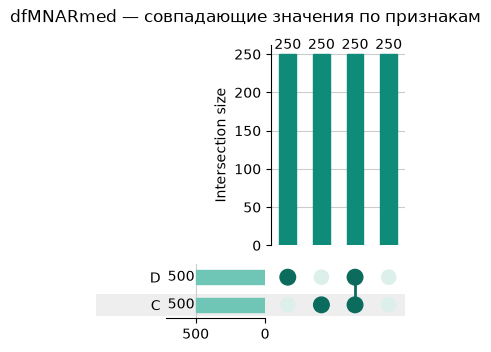

,dfMNARmed
D,250
C,250
C+D,250
—,250


In [31]:
display(Markdown("### [1.10] → [1.9](б) Совпадающие значения по признакам"))
res_mnar_dup = upset_series(stage_mnar, FEATURES, kind="duplicated",
                            outdir=str(FIG), prefix="1.10b")
plt.show()
if res_mnar_dup:
    display(intersections_table(res_mnar_dup, top=16))

UpSet (а) на `dfMNAR` показывает структуру, которой в MCAR-семействе не было:
пропуски `C` и `D` не независимы — они сцеплены через общую причину (значение
ниже медианы), и доля объектов, где пропали **оба**, заметно выше произведения
отдельных долей. Именно эта непроизводность на картинке и есть признак MNAR.

## Выводы

1. **[1.1]** Один класс из 1000 объектов, один вызов `multivariate_normal`:
   выборочная `r(A,B)` близка к заказанным 0.9, остальные пары около нуля —
   ровно то, что требует условие.
2. **[1.6]** При MCAR оценки корреляции устойчивы: считаясь по выжившим парам,
   `r` держится до ~50% удалённых ячеек. Опасны не пропуски сами по себе, а их
   заполнение.
3. **[1.7]** Медиана — худший вариант для корреляций: она собирает объекты в
   крест по медианам и гасит `r` пропорционально доле пропусков.
4. **[1.8]** По RMSE на скрытых ячейках регрессия обычно лучшая, но она же
   сильнее всех **завышает** связь (ставит условное ожидание, срезая шум).
   MICE проигрывает по RMSE, потому что и не должен его минимизировать — он
   сохраняет дисперсию и даёт корректные оценки разброса. kNN — компромисс.
   Выбирать метод надо под задачу: точечное восстановление ячейки и оценка
   зависимостей — разные цели.
5. **[1.9]** UpSet отвечает на вопрос, который не виден ни в таблице
   `isna().sum()`, ни в heatmap пропусков: *какие признаки пропадают вместе*.
   На MCAR комбинации распределены как произведение долей, на MNAR — нет.
   В разрезе (б) он же ловит отпечаток заполнителя: константное заполнение
   создаёт группы объектов с буквально одинаковыми значениями.
6. **[1.10]** MNAR не лечится импутацией. Все четыре метода дают смещённые
   `mean`/`std` по `C` и `D`, потому что нижней половины распределения нет
   ни в одной наблюдённой ячейке — восстанавливать её не из чего.